# ToysAD-8K DS1 LocateAnything screen

This notebook applies the frozen DS0 LocateAnything settings to the fixed
100-scene DS1 screen. It runs one-image and 20-image gates before the
resumable 2,000-image job. The model receives opaque RGB records only.

Box accuracy is evaluated later in the protected evaluator. This notebook
records operational reliability, proposal geometry, runtime, memory,
retries and failures without opening labels or source identifiers. A
retry uses a different deterministic seed. Attempts 1 to 4 use the
pinned hybrid mode. Attempts 5 and 6 use the pinned slow mode only when
the preceding attempt was truncated. Every attempt keeps the same model
and 8,192-token generation limit.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `04.1 DS1 LocateAnything screen`  
Clean notebook SHA-256: `5c78ff7e44a5f4c2c13214bc1444e112778e1f86a5536821d4767024db06b8cd`  
Downloaded saved-output SHA-256: `48d0b16d6749c5c43c26aa028a9d1976c3748070672ca52b83c3ce2608f32791`


## Acceptance contract

The accepted run must use all 100 scenes and all 20 views, preserve the
frozen cohort membership and model revision, pass exact coverage and box
validity gates, reproduce the 20-image pilot, and finish aggregate-only
ClearML finalisation after inference.

In [1]:
from __future__ import annotations

import importlib.metadata
import json
import os
from pathlib import Path
import platform
import signal
import subprocess
import sys
import time

sys.dont_write_bytecode = True

from IPython.display import HTML, Image as NotebookImage, display


NOTEBOOK_RELATIVE = Path(
    "notebooks/detection-and-segmentation/toysad8k-ds1-locateanything/"
    "04.1-toysad8k-ds1-locateanything-screen.ipynb"
)
OUTPUT_ROOT = Path("/kaggle/working/toysad8k_ds1_locateanything_screen")
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/input").is_dir() else "local"
RUN_MODE = "model_inference" if EXECUTION_ENVIRONMENT == "kaggle" else "contract_smoke"
INFERENCE_STAGE = os.getenv(
    "VPI_INFERENCE_STAGE", "full" if EXECUTION_ENVIRONMENT == "kaggle" else "one_image"
).strip().lower()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

## Locate the pinned code and DS1 model input

In [2]:
def locate_code_root() -> Path:
    candidates = [Path.cwd(), *Path.cwd().parents]
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        candidates.extend(path for mounted in input_root.iterdir() for path in (mounted, mounted / "code"))
    configured = os.getenv("VPI_CODE_ROOT")
    if configured:
        candidates.insert(0, Path(configured).expanduser())
    for candidate in candidates:
        marker = candidate / "src/visual_peer_inspector/workflows/locateanything_ds1.py"
        if marker.is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the Visual Peer Inspector code snapshot")


def locate_model_input_root() -> Path:
    configured = os.getenv("VPI_MODEL_INPUT_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        candidates.extend(path.parent for path in input_root.rglob("neutral_corpus_manifest.jsonl"))
    candidates.extend((Path.cwd(), *Path.cwd().parents))
    for candidate in candidates:
        if (candidate / "neutral_corpus_manifest.jsonl").is_file():
            return candidate.resolve()
        if (candidate / "model-input/neutral_corpus_manifest.jsonl").is_file():
            return (candidate / "model-input").resolve()
    raise FileNotFoundError("Could not locate the DS1 model-safe input package")


CODE_ROOT = locate_code_root()
MODEL_INPUT_ROOT = locate_model_input_root()
sys.path.insert(0, str(CODE_ROOT / "src"))

from visual_peer_inspector.data.cohort_contract import DS1_SCREEN_CONTRACT
from visual_peer_inspector.data.model_safe_package import file_sha256
from visual_peer_inspector.models.locateanything import LocateAnythingConfiguration

print({
    "code_root": CODE_ROOT.name,
    "model_input_root": MODEL_INPUT_ROOT.name,
    "cohort": DS1_SCREEN_CONTRACT.cohort_id,
    "images": DS1_SCREEN_CONTRACT.image_count,
})

{'code_root': 'vpi-code-snapshot', 'model_input_root': 'vpi-toysad-ds1-screen100-model-input', 'cohort': 'toysad8k-development-screen-100-v1', 'images': 2000}


## Install the pinned inference dependencies

In [3]:
if RUN_MODE == "model_inference":
    requirement = CODE_ROOT / "requirements/locateanything-lock.txt"
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(requirement)],
        timeout=600,
    )

configuration = LocateAnythingConfiguration()
display({
    "model": configuration.model_id,
    "revision": configuration.model_revision,
    "prompt": configuration.prompt,
    "configuration_sha256": configuration.sha256,
    "run_mode": RUN_MODE,
    "inference_stage": INFERENCE_STAGE,
})

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.4/299.4 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 107.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 37.3 MB/s eta 0:00:00


{'model': 'nvidia/LocateAnything-3B',
 'revision': 'c32291ca5e996f5a7a485845b4f57a233936bba0',
 'prompt': 'object',
 'configuration_sha256': '97d08548683794ad781ac7885efb34de9be68b9b2cf9f2cd905cbd20c77a9636',
 'run_mode': 'model_inference',
 'inference_stage': 'full'}

## Restore a private checkpoint and run the disposable GPU watchdog

A prior partial checkpoint may be attached as a private Kaggle dataset.
The archive contains raw model responses and must never be public or
committed to GitHub. Before the main worker is loaded, a separate process
must load the model and finish one real image within the configured time.
A timed-out process group is terminated so its CUDA context cannot be reused.
Passing this gate proves only that this Kaggle runtime can process one image.
It is not a general claim that LocateAnything supports T4.

In [4]:
from visual_peer_inspector.models.locateanything import MODEL_PRODUCER_KIND
from visual_peer_inspector.workflows.locateanything_ds1 import import_ds1_checkpoint


input_manifest_sha256 = file_sha256(MODEL_INPUT_ROOT / "neutral_corpus_manifest.jsonl")
configured_checkpoint = os.getenv("VPI_LOCATEANYTHING_CHECKPOINT_ARCHIVE")
checkpoint_candidates = (
    [Path(configured_checkpoint).expanduser()]
    if configured_checkpoint
    else list(Path("/kaggle/input").rglob("ds1_locateanything_checkpoint.zip"))
    if Path("/kaggle/input").is_dir()
    else []
)
if len(checkpoint_candidates) > 1:
    raise RuntimeError("Attach only one private DS1 LocateAnything checkpoint archive")
checkpoint_import = None
checkpoint_import_provenance = {
    "imported": False,
    "verification_status": "not_applicable",
    "archive_sha256": None,
    "files": {},
}
if checkpoint_candidates:
    checkpoint_import = import_ds1_checkpoint(
        checkpoint_candidates[0],
        OUTPUT_ROOT,
        configuration_sha256=configuration.sha256,
        producer_kind=(
            MODEL_PRODUCER_KIND if RUN_MODE == "model_inference" else "contract_smoke"
        ),
        input_manifest_sha256=input_manifest_sha256,
    )
    checkpoint_import_provenance = {
        "imported": True,
        "verification_status": "passed",
        "archive_sha256": checkpoint_import["archive_sha256"],
        "checkpoint_schema_version": checkpoint_import["schema_version"],
        "cohort_id": checkpoint_import["cohort_id"],
        "membership_sha256": checkpoint_import["membership_sha256"],
        "configuration_sha256": checkpoint_import["configuration_sha256"],
        "execution_policy_sha256": checkpoint_import["execution_policy_sha256"],
        "producer_kind": checkpoint_import["producer_kind"],
        "input_manifest_sha256": checkpoint_import["input_manifest_sha256"],
        "files": dict(checkpoint_import["files"]),
    }
    display({"checkpoint_imported": True, "files": sorted(checkpoint_import["files"])})

watchdog_receipt = OUTPUT_ROOT / "disposable_preflight_receipt.json"
watchdog_result = {"status": "not_required", "reason": "contract_smoke"}
if RUN_MODE == "model_inference":
    watchdog_timeout = int(os.getenv("VPI_ONE_IMAGE_WATCHDOG_SECONDS", "900"))
    if not 120 <= watchdog_timeout <= 1800:
        raise ValueError("The one-image watchdog must be between 120 and 1,800 seconds")
    command = [
        sys.executable,
        str(CODE_ROOT / "scripts/run_locateanything_one_image_watchdog.py"),
        "--model-input-root",
        str(MODEL_INPUT_ROOT),
        "--receipt",
        str(watchdog_receipt),
    ]
    watchdog_environment = os.environ.copy()
    watchdog_environment["PYTHONPATH"] = str(CODE_ROOT / "src")
    process = subprocess.Popen(
        command,
        env=watchdog_environment,
        start_new_session=True,
    )
    watchdog_started = time.monotonic()
    while process.poll() is None:
        elapsed = time.monotonic() - watchdog_started
        if elapsed >= watchdog_timeout:
            os.killpg(process.pid, signal.SIGTERM)
            try:
                process.wait(timeout=20)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGKILL)
                process.wait(timeout=20)
            raise TimeoutError(
                f"LocateAnything disposable one-image gate exceeded {watchdog_timeout} seconds"
            )
        print(
            json.dumps(
                {"stage": "disposable_preflight", "elapsed_seconds": round(elapsed, 1)},
                sort_keys=True,
            ),
            flush=True,
        )
        time.sleep(15)
    if not watchdog_receipt.is_file():
        raise RuntimeError("The disposable one-image process did not write a receipt")
    watchdog_result = json.loads(watchdog_receipt.read_text(encoding="utf-8"))
    display(watchdog_result)
    if process.returncode != 0 or watchdog_result.get("status") != "passed":
        raise RuntimeError("The disposable one-image model gate failed")

{"elapsed_seconds": 0.0, "stage": "disposable_preflight"}
{"elapsed_seconds": 15.0, "stage": "disposable_preflight"}
{"elapsed_seconds": 27.278, "images": 2000, "stage": "input_verified"}
{"elapsed_seconds": 30.0, "stage": "disposable_preflight"}
{"elapsed_seconds": 45.0, "stage": "disposable_preflight"}
{"device": "cuda", "dtype": "torch.float16", "elapsed_seconds": 57.76, "stage": "dependencies_ready"}
{"elapsed_seconds": 57.76, "source_kind": "hub", "stage": "tokenizer_load_started"}
{"elapsed_seconds": 59.123, "stage": "tokenizer_ready"}
{"elapsed_seconds": 59.123, "source_kind": "hub", "stage": "processor_load_started"}
{"elapsed_seconds": 60.0, "stage": "disposable_preflight"}


/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:647: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(


{"elapsed_seconds": 60.879, "stage": "processor_ready"}
{"elapsed_seconds": 60.879, "source_kind": "hub", "stage": "model_weights_load_started"}


`torch_dtype` is deprecated! Use `dtype` instead!
Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

{"elapsed_seconds": 75.0, "stage": "disposable_preflight"}
{"elapsed_seconds": 90.0, "stage": "disposable_preflight"}


...

{"elapsed_seconds": 105.0, "stage": "disposable_preflight"}


Loading checkpoint shards: 100%|██████████| 2/2 [00:04<00:00,  2.48s/it]


{"elapsed_seconds": 106.127, "stage": "model_weights_loaded"}
{"device": "cuda", "elapsed_seconds": 106.127, "stage": "model_device_move_started"}
{"device": "cuda", "elapsed_seconds": 108.593, "stage": "model_ready"}


/root/.cache/huggingface/modules/transformers_modules/nvidia/LocateAnything_hyphen_3B/c32291ca5e996f5a7a485845b4f57a233936bba0/generate_utils.py:186: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  box_avg.append(torch.tensor(out_ref, dtype=x0.dtype, device=x0.device))


{'checkpoints': [{'elapsed_seconds': 27.278,
   'images': 2000,
   'stage': 'input_verified'},
  {'device': 'cuda',
   'dtype': 'torch.float16',
   'elapsed_seconds': 57.76,
   'stage': 'dependencies_ready'},
  {'elapsed_seconds': 57.76,
   'source_kind': 'hub',
   'stage': 'tokenizer_load_started'},
  {'elapsed_seconds': 59.123, 'stage': 'tokenizer_ready'},
  {'elapsed_seconds': 59.123,
   'source_kind': 'hub',
   'stage': 'processor_load_started'},
  {'elapsed_seconds': 60.879, 'stage': 'processor_ready'},
  {'elapsed_seconds': 60.879,
   'source_kind': 'hub',
   'stage': 'model_weights_load_started'},
  {'elapsed_seconds': 106.127, 'stage': 'model_weights_loaded'},
  {'device': 'cuda',
   'elapsed_seconds': 106.127,
   'stage': 'model_device_move_started'},
  {'device': 'cuda', 'elapsed_seconds': 108.593, 'stage': 'model_ready'}],
 'configuration_sha256': '97d08548683794ad781ac7885efb34de9be68b9b2cf9f2cd905cbd20c77a9636',
 'cuda_version': '12.8',
 'cudnn_version': '91002',
 'device_

## Load the worker

ClearML is not started here. Model loading and inference finish before
tracking begins, so a tracking outage cannot freeze the GPU job.

In [5]:
from visual_peer_inspector.models.locateanything import (
    LocateAnythingWorker,
    ProposalContractWorker,
)

load_checkpoints = []
load_started = time.perf_counter()

def record_load(stage: str, details: dict | None = None) -> None:
    load_checkpoints.append({
        "stage": stage,
        "elapsed_seconds": round(time.perf_counter() - load_started, 3),
        **dict(details or {}),
    })
    print(json.dumps(load_checkpoints[-1], sort_keys=True), flush=True)


if RUN_MODE == "model_inference":
    import torch

    if not torch.cuda.is_available():
        raise RuntimeError("Notebook 04.1 requires a Kaggle GPU")
    torch.cuda.reset_peak_memory_stats()
    device = torch.cuda.get_device_properties(0)
    device_summary = {
        "cuda_available": True,
        "device_count": torch.cuda.device_count(),
        "device_name": torch.cuda.get_device_name(0),
        "compute_capability": f"{device.major}.{device.minor}",
        "total_memory_gib": round(device.total_memory / (1024 ** 3), 3),
    }
    worker = LocateAnythingWorker(configuration, progress_callback=record_load)
else:
    device_summary = {"cuda_available": False, "device_count": 0}
    worker = ProposalContractWorker(configuration)

model_load_seconds = round(time.perf_counter() - load_started, 3)
display({"model_load_seconds": model_load_seconds, **device_summary})

{"device": "cuda", "dtype": "torch.float16", "elapsed_seconds": 9.1, "stage": "dependencies_ready"}
{"elapsed_seconds": 9.101, "source_kind": "hub", "stage": "tokenizer_load_started"}
{"elapsed_seconds": 9.729, "stage": "tokenizer_ready"}
{"elapsed_seconds": 9.73, "source_kind": "hub", "stage": "processor_load_started"}


/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:647: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(


{"elapsed_seconds": 11.056, "stage": "processor_ready"}
{"elapsed_seconds": 11.057, "source_kind": "hub", "stage": "model_weights_load_started"}


`torch_dtype` is deprecated! Use `dtype` instead!
Qwen2ForCausalLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

{"elapsed_seconds": 17.756, "stage": "model_weights_loaded"}
{"device": "cuda", "elapsed_seconds": 17.756, "stage": "model_device_move_started"}
{"device": "cuda", "elapsed_seconds": 20.048, "stage": "model_ready"}


{'model_load_seconds': 20.049,
 'cuda_available': True,
 'device_count': 2,
 'device_name': 'Tesla T4',
 'compute_capability': '7.5',
 'total_memory_gib': 14.562}

## Run the preflight, repeatability gate and resumable proposal job

In [6]:
from visual_peer_inspector.verification import verify_code_snapshot_record
from visual_peer_inspector.workflows.locateanything_ds1 import (
    run_ds1_locateanything_workflow,
)

snapshot_path = CODE_ROOT / "snapshot_record.json"
if RUN_MODE == "model_inference" and INFERENCE_STAGE == "full" and not snapshot_path.is_file():
    raise RuntimeError("A canonical full run requires snapshot_record.json")
snapshot = verify_code_snapshot_record(CODE_ROOT, snapshot_path) if snapshot_path.is_file() else {}
notebook_path = CODE_ROOT / NOTEBOOK_RELATIVE
if RUN_MODE == "model_inference" and INFERENCE_STAGE == "full":
    if snapshot.get("git_dirty") is not False or snapshot.get("precommit_candidate") is not False:
        raise RuntimeError("A canonical full run requires a clean committed code snapshot")
    if not notebook_path.is_file():
        raise RuntimeError("The code snapshot must include the exact Notebook 04.1 source")
snapshot_versions = snapshot.get("platform_versions", {})


def required_version(key: str) -> str:
    value = os.getenv(f"VPI_{key.upper()}") or snapshot_versions.get(key)
    if not value or str(value).strip().lower() in {"pending", "unknown", "unavailable"}:
        if RUN_MODE == "model_inference" and INFERENCE_STAGE == "full":
            raise RuntimeError(f"The code snapshot is missing version pin: {key}")
        return "local-contract"
    return str(value)


version_pins = {
    key: required_version(key)
    for key in ("kaggle_notebook_version_04_1", "code_dataset_version")
}
provenance = {
    "git_commit": snapshot.get("git_commit", "local-contract"),
    "git_dirty": snapshot.get("git_dirty", True),
    "precommit_candidate": snapshot.get("precommit_candidate", True),
    "snapshot_sha256": snapshot.get("snapshot_sha256", ""),
    "notebook_sha256": (
        __import__("hashlib").sha256(notebook_path.read_bytes()).hexdigest()
        if notebook_path.is_file() else ""
    ),
    "kaggle_notebook_slug": "esreekarreddy/toysad-8k-ds1-locateanything-screen",
    "checkpoint_import": checkpoint_import_provenance,
    **version_pins,
}
platform_versions = {
    "python": platform.python_version(),
    "pillow": importlib.metadata.version("Pillow"),
    "numpy": importlib.metadata.version("numpy"),
    "transformers": (
        importlib.metadata.version("transformers")
        if RUN_MODE == "model_inference" else "not-loaded"
    ),
    "torch": (
        importlib.metadata.version("torch")
        if RUN_MODE == "model_inference" else "not-loaded"
    ),
    "torchvision": (
        importlib.metadata.version("torchvision")
        if RUN_MODE == "model_inference" else "not-loaded"
    ),
    "cuda_runtime": (
        str(torch.version.cuda) if RUN_MODE == "model_inference" else "not-loaded"
    ),
    "cudnn": (
        str(torch.backends.cudnn.version())
        if RUN_MODE == "model_inference" else "not-loaded"
    ),
    "kaggle_container_image": os.getenv("KAGGLE_CONTAINER_IMAGE", "unavailable"),
    "kaggle_kernel_run_type": os.getenv("KAGGLE_KERNEL_RUN_TYPE", "unavailable"),
    **version_pins,
}
load_evidence = {
    "load_seconds": model_load_seconds,
    "download_seconds": 0.0,
    "checkpoints": load_checkpoints,
    "disposable_preflight": watchdog_result,
    "device": device_summary,
    "peak_gpu_allocated_gib": (
        round(torch.cuda.max_memory_allocated() / (1024 ** 3), 4)
        if RUN_MODE == "model_inference" else 0.0
    ),
    "peak_gpu_reserved_gib": (
        round(torch.cuda.max_memory_reserved() / (1024 ** 3), 4)
        if RUN_MODE == "model_inference" else 0.0
    ),
}
run_record = run_ds1_locateanything_workflow(
    model_input_root=MODEL_INPUT_ROOT,
    output_root=OUTPUT_ROOT,
    worker=worker,
    configuration=configuration,
    run_mode=RUN_MODE,
    inference_stage=INFERENCE_STAGE,
    provenance=provenance,
    platform_versions=platform_versions,
    model_load_evidence=load_evidence,
)
display({
    "status": run_record["status"],
    "images": run_record["summary"]["job_count"],
    "successful": run_record["summary"]["successful_job_count"],
    "repeat_agreement": run_record["repeat_agreement"].get("box_agreement_rate"),
})

/root/.cache/huggingface/modules/transformers_modules/nvidia/LocateAnything_hyphen_3B/c32291ca5e996f5a7a485845b4f57a233936bba0/generate_utils.py:186: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  box_avg.append(torch.tensor(out_ref, dtype=x0.dtype, device=x0.device))


{"completed": 1, "elapsed_seconds": 19.329, "failed": 0, "stage": "proposal_progress", "successful": 1, "total": 2000}
{"completed": 100, "elapsed_seconds": 62.562, "failed": 0, "stage": "proposal_progress", "successful": 100, "total": 2000}
{"completed": 200, "elapsed_seconds": 102.589, "failed": 0, "stage": "proposal_progress", "successful": 200, "total": 2000}
{"completed": 300, "elapsed_seconds": 144.875, "failed": 0, "stage": "proposal_progress", "successful": 300, "total": 2000}
{"completed": 400, "elapsed_seconds": 185.221, "failed": 0, "stage": "proposal_progress", "successful": 400, "total": 2000}
{"completed": 500, "elapsed_seconds": 225.902, "failed": 0, "stage": "proposal_progress", "successful": 500, "total": 2000}
{"completed": 600, "elapsed_seconds": 391.364, "failed": 0, "stage": "proposal_progress", "successful": 600, "total": 2000}
{"completed": 700, "elapsed_seconds": 437.22, "failed": 0, "stage": "proposal_progress", "successful": 700, "total": 2000}
{"completed": 8

{'status': 'completed',
 'images': 2000,
 'successful': 2000,
 'repeat_agreement': 1.0}

## Review aggregate operational evidence

,gate,status,observed,expected
0,preflight images,pass,1.0,1.0
1,preflight successes,pass,1.0,1.0
2,preflight failures,pass,0.0,0.0
3,preflight truncated responses,pass,0.0,0.0
4,preflight zero-proposal successes,pass,0.0,0.0
5,pilot images,pass,20.0,20.0
6,pilot successes,pass,20.0,20.0
7,pilot failures,pass,0.0,0.0
8,pilot scene coverage,pass,20.0,20.0
9,pilot truncated responses,pass,0.0,0.0


,view_id,image_count,successful_count,failed_count,mean_proposal_count,mean_runtime_seconds,truncated_count
0,V00,100,100,0,3.77,0.4236,0
1,V01,100,100,0,3.80,0.4234,0
2,V02,100,100,0,3.80,0.4232,0
3,V03,100,100,0,4.44,0.5843,0
4,V04,100,100,0,4.60,0.6683,0
5,V05,100,100,0,5.31,0.5679,0
6,V06,100,100,0,3.81,0.4329,0
7,V07,100,100,0,5.99,0.6373,0
8,V08,100,100,0,3.78,0.4463,0
9,V09,100,100,0,8.78,0.8651,0


,error_type,count
0,PossibleTruncation,8


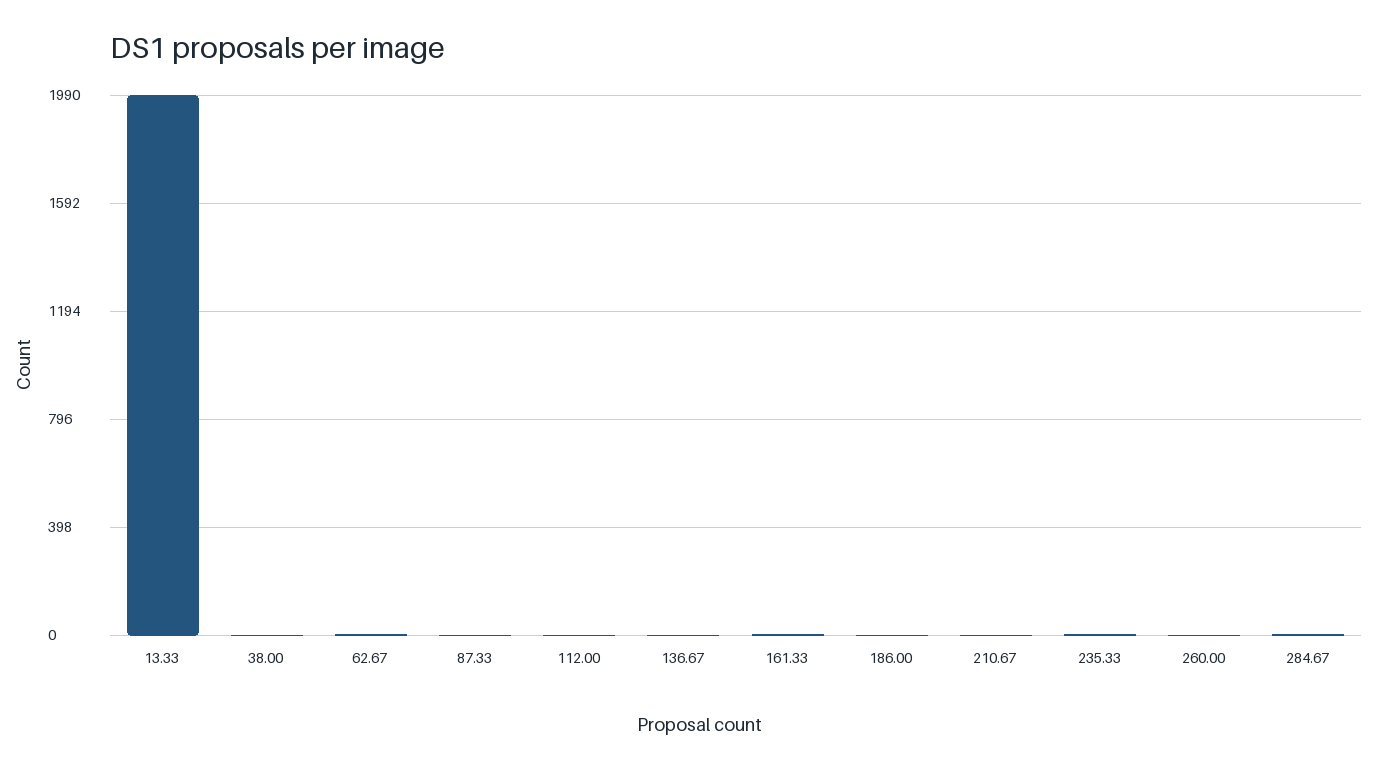

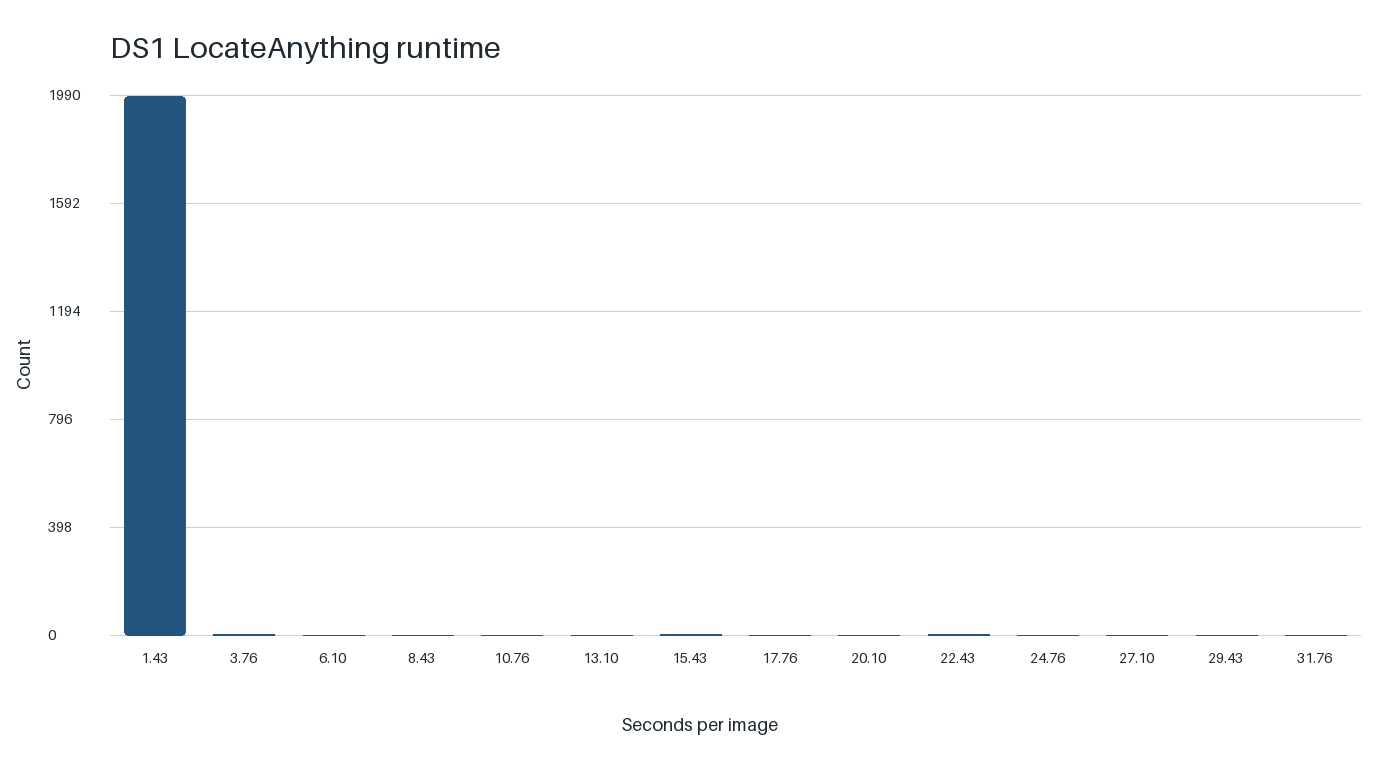

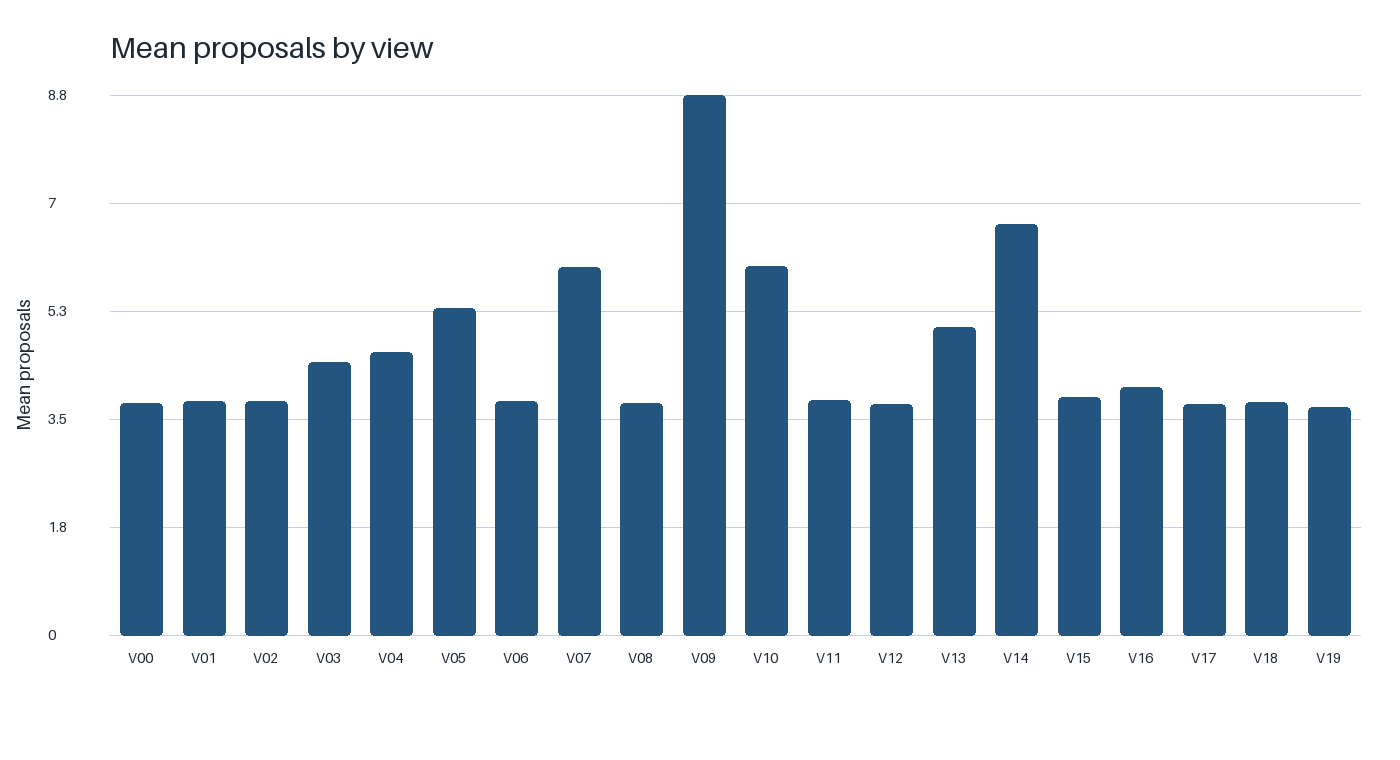

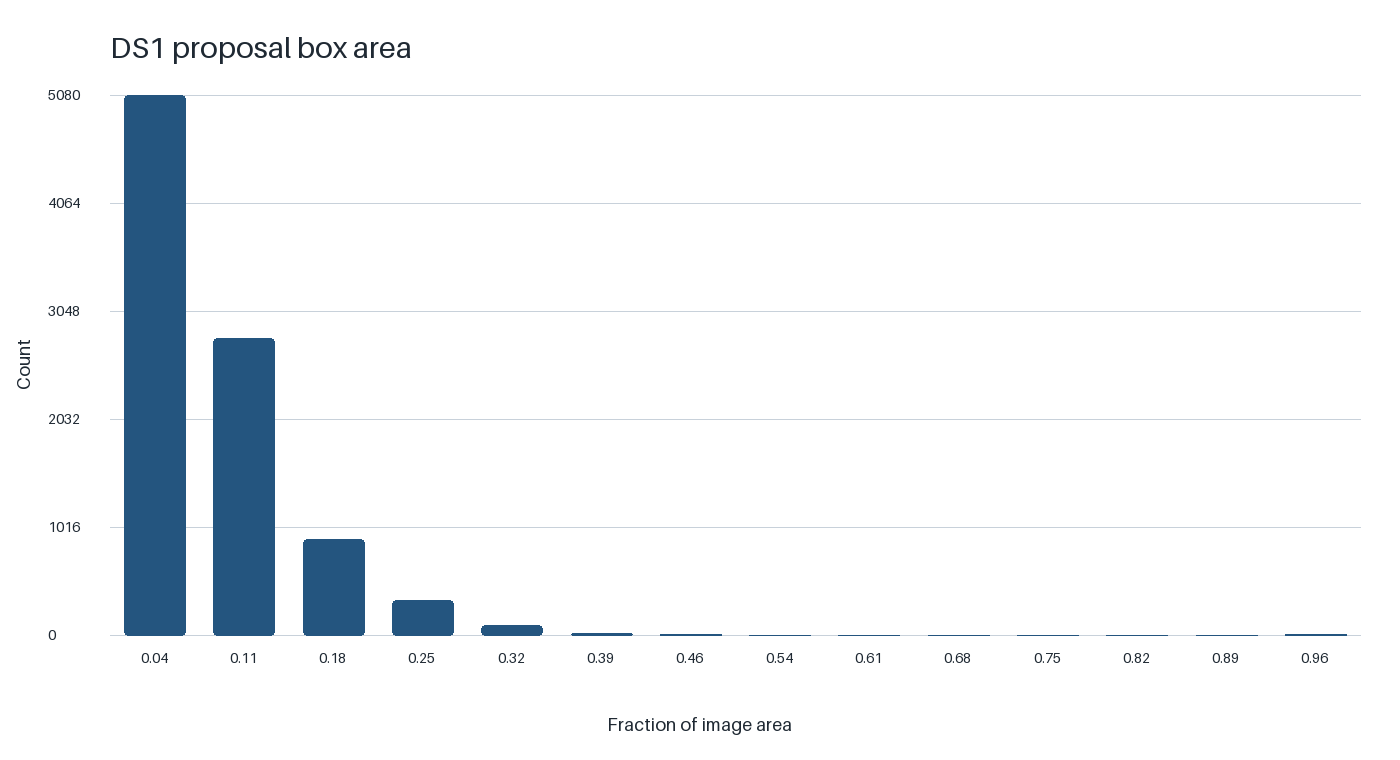

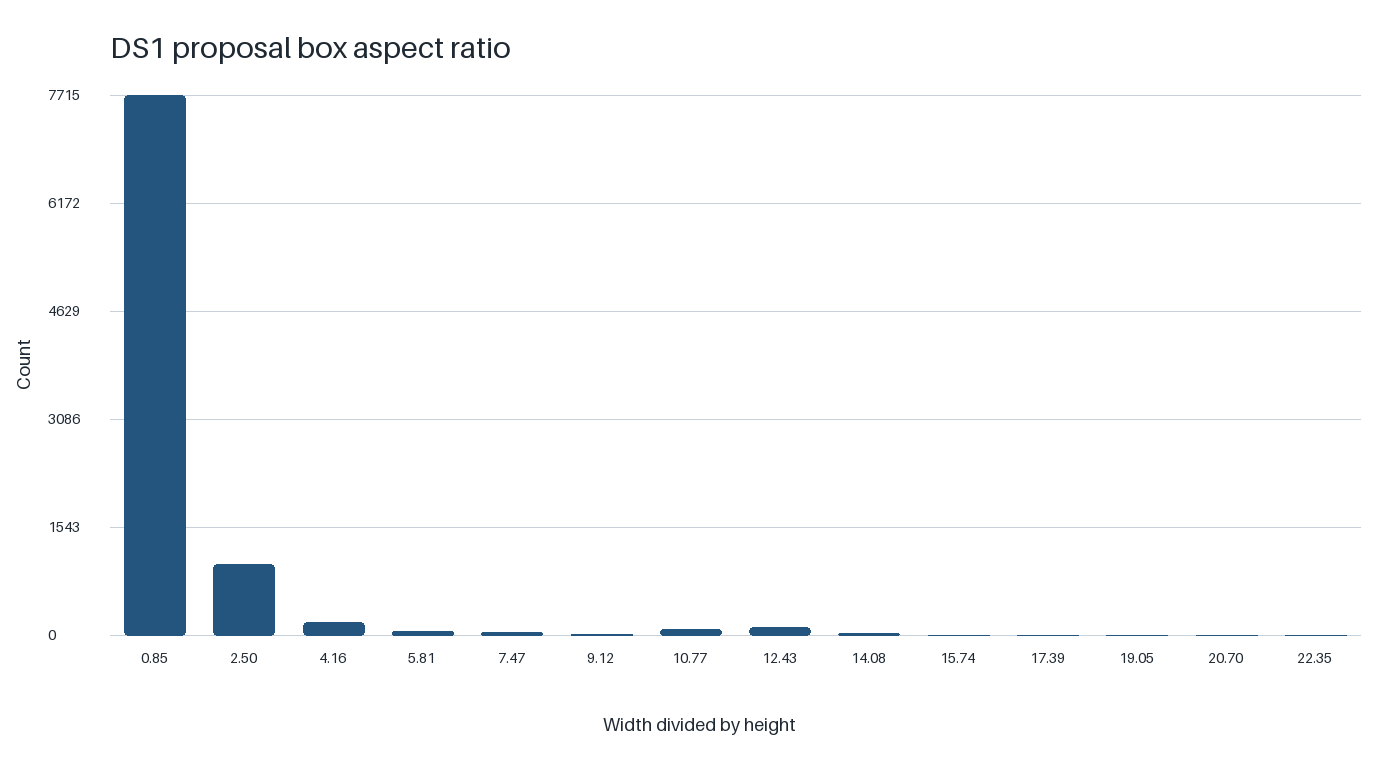

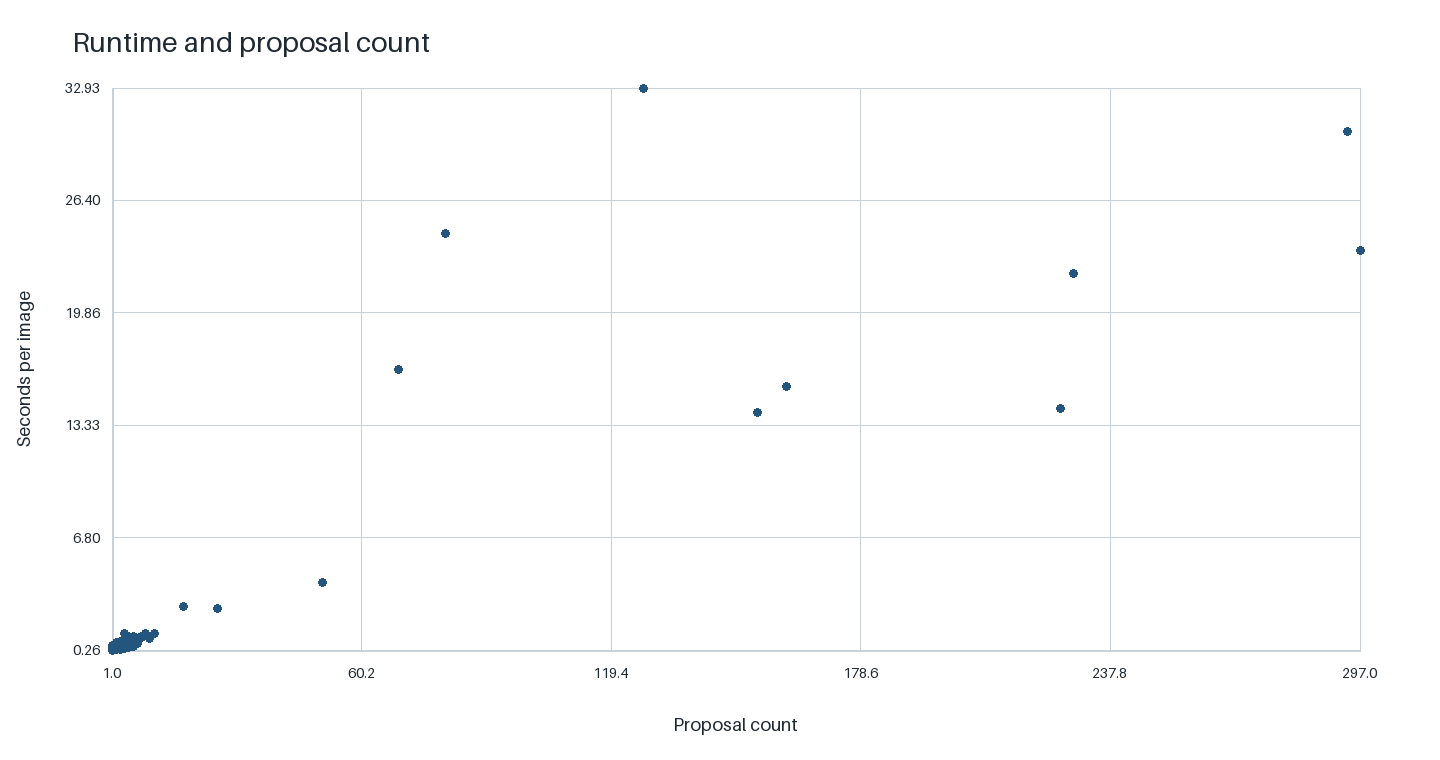

In [7]:
import pandas as pd

safe_root = OUTPUT_ROOT / "safe"
display(HTML("<h4>Completion gates</h4>"))
display(pd.read_csv(safe_root / "completion_gates.csv"))
display(HTML("<h4>Proposal summary by view</h4>"))
display(pd.read_csv(safe_root / "proposal_summary_by_view.csv"))
display(HTML("<h4>Failure summary</h4>"))
display(pd.read_csv(safe_root / "failure_summary.csv"))

for name in (
    "proposal_count_distribution.png",
    "runtime_distribution.png",
    "mean_proposals_by_view.png",
    "box_area_fraction_distribution.png",
    "box_aspect_ratio_distribution.png",
    "runtime_by_proposal_count.png",
):
    display(NotebookImage(filename=str(safe_root / name)))

## Private visual review

The panel below is retained with the private run output. It is not sent
to ClearML or committed to GitHub.

In [8]:
example_path = OUTPUT_ROOT / "private/proposal_examples.png"
if example_path.is_file():
    display(NotebookImage(filename=str(example_path)))
    outlier_path = OUTPUT_ROOT / "private/proposal_outliers.png"
    if outlier_path.is_file():
        display(NotebookImage(filename=str(outlier_path)))
    if RUN_MODE == "contract_smoke":
        print("These are synthetic contract-smoke boxes, not LocateAnything predictions.")
else:
    print("Proposal examples are generated by the full run only.")

<IPython.core.display.Image object>

<IPython.core.display.Image object>

## Export restart state

The archive below can be uploaded as a private Kaggle dataset and attached
to a fresh version. It contains private raw responses. Keep it outside
GitHub, ClearML and public Kaggle datasets.

In [9]:
from visual_peer_inspector.workflows.locateanything_ds1 import export_ds1_checkpoint


checkpoint_export = export_ds1_checkpoint(
    OUTPUT_ROOT,
    Path("/kaggle/working/ds1_locateanything_checkpoint.zip"),
    configuration_sha256=configuration.sha256,
    producer_kind=run_record["producer_kind"],
    input_manifest_sha256=run_record["cohort"]["input_manifest_sha256"],
)
display({
    "checkpoint_file_count": len(checkpoint_export["files"]),
    "checkpoint_archive_sha256": checkpoint_export["archive_sha256"],
})

{'checkpoint_file_count': 4,
 'checkpoint_archive_sha256': '86790430c95a612e5c33df9d284ff8e36d064f9d69fff534368ed45b6bb5d777'}

## Finalise aggregate ClearML evidence

This isolated, wall-time-bounded child uses the official ClearML hosts.
It retries only transient task-creation connection failures and writes
sanitized retry counts and failure categories to the receipt.

In [10]:
tracking_mode = os.getenv(
    "VPI_TRACKING_MODE", "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled"
).strip().lower()
tracking_environment = os.environ.copy()

tracking_receipt = OUTPUT_ROOT / "tracking_receipt.json"
command = [
    sys.executable,
    str(CODE_ROOT / "scripts/finalize_locateanything_ds1_clearml.py"),
    "--safe-root",
    str(safe_root),
    "--receipt",
    str(tracking_receipt),
    "--mode",
    tracking_mode,
    "--wall-time-seconds",
    "180",
    "--tag",
    "notebook-04.1",
    "--tag",
    "ds1",
]
try:
    subprocess.run(command, check=True, env=tracking_environment, timeout=210)
    tracking_result = json.loads(tracking_receipt.read_text(encoding="utf-8"))
except Exception as error:
    tracking_result = {
        "schema_version": 1,
        "stage": "notebook_04_1_clearml_finalisation",
        "mode": tracking_mode,
        "status": "failed",
        "task_id": None,
        "error_type": type(error).__name__,
    }
    tracking_receipt.write_text(
        json.dumps(tracking_result, indent=2, sort_keys=True) + "\n",
        encoding="utf-8",
    )
display(tracking_result)
if tracking_result["status"] == "failed":
    print("ClearML finalisation failed after compute. Model outputs remain complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00


{'clearml_hosts': {'CLEARML_API_HOST': 'https://api.clear.ml',
  'CLEARML_FILES_HOST': 'https://files.clear.ml',
  'CLEARML_WEB_HOST': 'https://app.clear.ml'},
 'mode': 'online',
 'run_status': 'completed',
 'safe_manifest_sha256': '2304e4b81ed5ae1e4423e9f784a42c9aad482e6d09c2c29d1465ed7f6c50b461',
 'schema_version': 1,
 'stage': 'notebook_04_1_clearml_finalisation',
 'status': 'failed',
 'task_id': None,
 'tracking_attempt_count': 0,
 'tracking_error_category': 'internal_error',
 'tracking_error_type': 'ConnectionError',
 'tracking_retry_count': 0,
 'tracking_transient_failure_count': 0}

ClearML finalisation failed after compute. Model outputs remain complete.


## Completion

In [11]:
from visual_peer_inspector.workflows.locateanything_ds1 import write_artifact_manifest

manifest = write_artifact_manifest(safe_root)
final_summary = {
    "run_status": run_record["status"],
    "completion_gate_passed": run_record["completion_gate_passed"],
    "safe_artifact_count": manifest["artifact_count"],
    "tracking_status": tracking_result["status"],
    "clearml_task_id": tracking_result.get("task_id"),
    "private_results": str(OUTPUT_ROOT / "private/proposal_results.jsonl"),
}
display(final_summary)
if INFERENCE_STAGE == "full" and not run_record["completion_gate_passed"]:
    print(
        "Acceptance failed. The evidence and private checkpoint are downloadable, "
        "but this run is not promotable and must not feed the SAM stage."
    )

{'run_status': 'completed',
 'completion_gate_passed': True,
 'safe_artifact_count': 24,
 'tracking_status': 'failed',
 'clearml_task_id': None,
 'private_results': '/kaggle/working/toysad8k_ds1_locateanything_screen/private/proposal_results.jsonl'}

The next trusted step joins the frozen proposal file to protected reference
geometry. The model-facing SAM package receives only opaque image keys and
reference-box or automatic-box prompts.